


# Vamos encher o carrinho!

# Introdução

O Instacart é uma plataforma de entrega de supermercado onde os clientes podem fazer um pedido no supermercado e depois receber sua compra, semelhante ao funcionamento do Uber Eats e do iFood. O conjunto de dados que fornecemos foi modificado a partir do original. Reduzimos o tamanho dele para que seus cálculos sejam executados mais rapidamente e incluímos valores ausentes e duplicados. Também tivemos o cuidado de preservar as distribuições dos dados originais quando fizemos as alterações.

Você precisa completar três etapas. Para cada uma delas, escreva uma breve introdução descrevendo como você pretende concluir a etapa e justifique suas decisões em parágrafos explicativos a medida que você avança na solução. Escreva também uma conclusão para resumir suas conclusões e escolhas.



## Dicionário de dados

Há cinco tabelas no conjunto de dados, e você vai precisar usar todas elas para pré-processar seus dados e fazer AED. Abaixo está um dicionário que lista as colunas de cada tabela e descreve os dados contidos nelas.

- `instacart_orders.csv`: cada linha corresponde a um pedido no aplicativo da Instacart
    - `'order_id'`: é o número que identifica cada pedido de forma exclusiva
    - `'user_id'`: é o número de identificação exclusivo da conta de cada cliente
    - `'order_number'`: é o número de vezes que o cliente fez um pedido
    - `'order_dow'`: é o dia da semana em que o pedido foi feito (0 é domingo)
    - `'order_hour_of_day'`: é a hora do dia em que o pedido foi feito
    - `'days_since_prior_order'`: é o número de dias desde que o cliente fez seu pedido anterior




- `products.csv`: cada linha corresponde a um produto exclusivo que os clientes podem comprar
    - `'product_id'`: é o número de identificação unívoco de cada produto
    - `'product_name'`: é o nome do produto
    - `'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    - `'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado




-	`order_products.csv`: cada linha corresponde a um item incluído em um pedido
    -	`'order_id'`: é o número que identifica cada pedido de forma exclusiva
    -	`'product_id'`: é o número de identificação exclusivo de cada produto
    -	`'add_to_cart_order'`: é a ordem sequencial em que cada item foi colocado no carrinho
    -	`'reordered'`: 0 se o cliente nunca comprou o produto antes, 1 se já o comprou




-	`aisles.csv`
    -	`'aisle_id'`: é o número de identificação exclusivo de cada categoria de corredor do supermercado
    -	`'aisle'`: é o nome do corredor



-	`departments.csv`
    -	`'department_id'`: é o número de identificação exclusivo de cada categoria de departamento do supermercado
    -	`'department'`: é o nome do departamento


# Etapa 1. Visão geral dos dados

Leia os arquivos de dados (/datasets/instacart_orders.csv, /datasets/products.csv, /datasets/aisles.csv, /datasets/departments.csv e /datasets/order_products.csv) com `pd.read_csv()` usando os parâmetros apropriados para fazer isso corretamente. Verifique as informações para cada DataFrame criado.


## Plano de solução

Escreva aqui seu plano para a Etapa 2. Visão geral dos dados

In [1]:
import pandas as pd # Importe as bibliotecas

In [2]:
df_orders = pd.read_csv('/datasets/instacart_orders.csv', sep=';')
df_products = pd.read_csv('/datasets/products.csv', sep= ';')
df_aisles = pd.read_csv('/datasets/aisles.csv', ';')
df_departments = pd.read_csv('/datasets/departments.csv', sep=';')
df_order_products = pd.read_csv('/datasets/order_products.csv', sep=';')

In [3]:
df_orders.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


In [4]:
df_products.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


In [5]:
df_aisles.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


In [6]:
df_departments.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes


In [7]:
df_order_products.info()# imprima as informações sobre o DataFrame

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 1. Visão geral dos dados
-As colunas dos df estavam sendo separadas por ; então tive que colocar um parametro extra, para arrumar os df arrumando as colunas, olhando os df encontrei algumas colunas com valores ausentes, na ordem de produtos o ultimo df está daltando os dados das linhas está apenas a coluna e o tipo de dados, no df_orders está dalatando algus numeros pois na coluna de days_since_prior_order está com numeros nulos, assim como no df_products a coluna de product_name está com alguns numeros nulos.

# Etapa 2. Preparação de dados

Faça o pré-processamento dos dados da seguinte maneira:

-	Verifique e corrija os tipos de dados (por exemplo, certifique-se de que as colunas de ID sejam números inteiros)
-	Identifique e preencha valores ausentes
-	Identifique e remova valores duplicados

Certifique-se de explicar que tipos de valores ausentes e duplicados você encontrou, como você os preencheu ou removeu, por que escolheu esses métodos e por que você acha que esses valores ausentes e duplicados estavam presentes no conjunto de dados.

## Plano de solução

Escreva aqui seu plano para a Etapa 2. Preparação de dados
- Encontrar os valores duplicados ou ausentes no meu df, analisar e ver os valores duplicados e ver o tipo de dados, depois remover os valores duplicados.

## Encontre e remova valores duplicados (e descreva por que você está fazendo suas escolhas)

### DataFrame `instacart_orders`

In [8]:
df_orders[df_orders.duplicated()]# Verificar se há pedidos duplicados

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
145574,794638,50898,24,3,2,2.0
223105,2160484,107525,16,3,2,30.0
230807,1918001,188546,14,3,2,16.0
266232,1782114,106752,1,3,2,NaN
273805,1112182,202304,84,3,2,6.0
284038,2845099,31189,11,3,2,7.0
311713,1021560,53767,3,3,2,9.0
321100,408114,68324,4,3,2,18.0
323900,1919531,191501,32,3,2,7.0
345917,2232988,82565,1,3,2,NaN


Há linhas duplicadas? Se sim, o que elas têm em comum?
#Existe linhas duplicadas, por que todos os pedidos foram feitos no mesmo horário e no mesmo dia, a coluna order_dow e order_hour_of_day estão iguais em todas as linhas.

In [9]:

df_orders = df_orders[(df_orders['order_dow'] == 3) &  ( df_orders['order_hour_of_day']== 2)]
print(df_orders)


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

O que esse resultado quer dizer? Que os pedidos de quarta feira a noite estão duplicados.

In [10]:


df_orders = pd.read_csv('/datasets/instacart_orders.csv', sep=';')
df_orders = df_orders.drop_duplicates()
print(df_orders)
# Remova pedidos duplicados


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
0        1515936   183418            11          6                 13   
1        1690866   163593             5          5                 12   
2        1454967    39980             4          5                 19   
3        1768857    82516            56          0                 20   
4        3007858   196724             2          4                 12   
...          ...      ...           ...        ...                ...   
478962   3210681     5617             5          1                 14   
478963   3270802   112087             2          3                 13   
478964    885349    82944            16          2                 11   
478965    216274     4391             3          3                  8   
478966   2071924     1730            18          1                 14   

        days_since_prior_order  
0                         30.0  
1                          9.0  
2                       

In [11]:
df_orders = pd.read_csv('/datasets/instacart_orders.csv', sep=';')
df_orders = df_orders.drop_duplicates()
print(df_orders)# Verifique as linhas duplicadas mais uma vez

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
0        1515936   183418            11          6                 13   
1        1690866   163593             5          5                 12   
2        1454967    39980             4          5                 19   
3        1768857    82516            56          0                 20   
4        3007858   196724             2          4                 12   
...          ...      ...           ...        ...                ...   
478962   3210681     5617             5          1                 14   
478963   3270802   112087             2          3                 13   
478964    885349    82944            16          2                 11   
478965    216274     4391             3          3                  8   
478966   2071924     1730            18          1                 14   

        days_since_prior_order  
0                         30.0  
1                          9.0  
2                       

In [12]:
df_orders[df_orders['order_id'].duplicated()]# Verifique novamente apenas os IDs de pedidos duplicados

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order




Descreva brevemente suas conclusões e o que você fez com elas.
com os primeiros dados, vi que tinha pedidos duplicados da quarta feira as 2h então eu tirei todos os pedidos duplicados desse periodo e logo depois imprimi apenas a columas order id para ter certeza que não tem mais pedidos duplicados

### DataFrame `products`

In [13]:
df_products[df_products.duplicated()]# Verifique se há linhas completamente duplicadas

,product_id,product_name,aisle_id,department_id


In [14]:
df_products[(df_products['product_id'].duplicated())]# Verifique apenas IDs dos produtos duplicados

,product_id,product_name,aisle_id,department_id


In [15]:
df_products[(df_products['product_name'].str.lower().duplicated())]# Verifique apenas nomes de produtos duplicados (converta os nomes para minúsculas para uma comparação melhor)

,product_id,product_name,aisle_id,department_id
71,72,NaN,100,21
109,110,NaN,100,21
296,297,NaN,100,21
416,417,NaN,100,21
436,437,NaN,100,21
...,...,...,...,...
49689,49690,HIGH PERFORMANCE ENERGY DRINK,64,7
49690,49691,ORIGINAL PANCAKE & WAFFLE MIX,130,14
49691,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,130,14
49692,49693,SPRING WATER BODY WASH,127,11


In [16]:
df_products[(df_products['product_name'].str.lower().duplicated()) & (~df_products['product_name'].isna())]
# Verifique os nomes de produtos duplicados que não estão faltando

,product_id,product_name,aisle_id,department_id
2058,2059,Biotin 1000 Mcg,47,11
5455,5456,Green Tea With Ginseng and Honey,96,20
5558,5559,Cream Of Mushroom Soup,69,15
7558,7559,Cinnamon Rolls with Icing,105,13
9037,9038,American Cheese slices,21,16
...,...,...,...,...
49689,49690,HIGH PERFORMANCE ENERGY DRINK,64,7
49690,49691,ORIGINAL PANCAKE & WAFFLE MIX,130,14
49691,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,130,14
49692,49693,SPRING WATER BODY WASH,127,11


Descreva brevemente suas conclusões e o que você fez com elas.
- Não tinha valores duplicados, mas tinha nomes duplicados, isso quer dizer que tem produtos diferentes com o mesmo nome.

### DataFrame `departments`

In [17]:
df_departments[df_departments.duplicated()]# Verifique se há linhas completamente duplicadas

,department_id,department


### DataFrame `aisles`

In [18]:
df_aisles[df_aisles.duplicated()]# Verifique se há linhas completamente duplicadas

,aisle_id,aisle


In [19]:
df_aisles[df_aisles['aisle_id'].duplicated()]# Verifique apenas IDs duplicados de corredores

,aisle_id,aisle


Descreva brevemente suas conclusões e o que você fez com elas.
-Que não existe numero duplicados,então o df está totalmente limpo para analise, primeiro procurei por linhas duplicados e apareceu limpo, logo depois filtrei a coluna com os id para confirmar se o df estava limpo, assim não tento nenhum id também duplicados no df 

### DataFrame `order_products`

In [20]:
df_order_products[df_order_products.duplicated()]# Verifique se há linhas completamente duplicadas

,order_id,product_id,add_to_cart_order,reordered


In [21]:
df_order_products[df_order_products.duplicated(subset=['order_id', 'product_id'])]
# Verifique mais uma vez se há outros casos complicados de duplicados

,order_id,product_id,add_to_cart_order,reordered


Descreva brevemente suas conclusões e o que você fez com elas.
-Não tinha produtos duplicados com a primeira busca, logo depois garanti que não havia produtos duplicados no df com as colunas onde poderia ter o produto aparecendo duas vezes.

## Encontre e remova valores ausentes


Ao processarmos valores duplicados, observamos que também temos valores ausentes que precisamos investigar nas seguintes colunas:

*	A coluna `'product_name'` da tabela products.
*	A coluna `'days_since_prior_order'` da tabela orders.
*	A coluna `'add_to_cart_order'` da tabela order_products.


### DataFrame `products`

In [22]:

df_products['product_name'].isna().sum()
# Encontre valores ausentes na coluna 'product_name'

1258

Descreva brevemente suas conclusões.
Tem 1258 valores nulos no nosso df_products

In [23]:
df_products[df_products['product_name'].isna()]['aisle_id'].unique()

array([100])

Descreva brevemente suas conclusões.
Todos os produtos os produtos com nome ausente estão no corredor com id=100 por que o unique somou todos os valores diferentes e deu array 100 no resultado que diz que todos os valores estão no corredor 100, se tivesse em outros corredores iriam ter mais resultados dentro da lista.

In [24]:
df_products[df_products['product_name'].isna()]['department_id'].unique()# Todos os nomes de produtos ausentes estão associados com o departamento de ID 21?

array([21])

Descreva brevemente suas conclusões.
- Usei a mesma lógica de cima, para procurar os nomes ausentes com o método unique com isso me deu a resposta de array 21, com isso conclusão de todos os nomes de produtos ausentes estão associados ao departamento 21 

In [25]:
df_aisles[df_aisles['aisle_id'] == 100]
df_departments[df_departments['department_id'] == 21]
print(df_aisles[df_aisles['aisle_id'] == 100])
print(df_departments[df_departments['department_id'] == 21])
# Use as tabelas department e aisle para verificar os dados do corredor com ID 100 e do departamento com ID 21.

    aisle_id    aisle
99       100  missing
    department_id department
20             21    missing


Descreva brevemente suas conclusões.
- Dados ausentes podem alterar a analise, pois eles contam como valores na hora da analise e eles não tem valores.

In [26]:
df_products['product_name'] = df_products['product_name'].fillna('Unknown')
# Preencha nomes de produtos ausentes com 'Unknown'

Descreva brevemente suas conclusões e o que você fez com elas.
-Com os nomes duplicados dos produtos dos corredores e do departamento, poderia analisar os dados errados contanto mais produtos do que tinha, pois como eles não tem nome eles podem ser contato como outro produto, ou não ter o produto.

### DataFrame `orders`

In [27]:
df_orders.isna().sum()# Encontre os valores ausentes

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64

In [28]:
df_orders['days_since_prior_order'].isna().sum()# Há valores ausentes para os clientes que não estão fazendo o primeiro pedido?

28817

Descreva brevemente suas conclusões e o que você fez com elas.
-Todos os valores ausentes que tem do df orders, está na coluna days_since_prior_order, não temos dados sobre os ultimos dias que os clientes fizeram pedidos.

### DataFrame `order_products`

In [29]:
df_order_products.isna().sum()# Encontre os valores ausentes

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64

In [30]:


df_order_products['add_to_cart_order'].min()
df_order_products['add_to_cart_order'].max()
print("Mínimo:", df_order_products['add_to_cart_order'].min(), "Máximo:", df_order_products['add_to_cart_order'].max())

# Quais são os valores mínimo e máximo dessa coluna?

Mínimo: 1.0 Máximo: 64.0


Descreva brevemente suas conclusões.
a coluna com as ordem dos pedidos no carrinho estão com numeros ausentes, assim não sabendo se todos os itens das compras foram passados, ou se não foi passado compras de outros ids na mesma. o valor maximo de produtos é 64 então os numeros que são mais não conseguem ser regristrados e ficam como NAN dando erro na analise, por isso a limpeza dos numeros ausentes.

In [31]:
add_to_cart_order = df_order_products[df_order_products['add_to_cart_order'].isna()]['order_id']
print(add_to_cart_order)# Salve todos os IDs dos pedidos com pelo menos um valor ausente em 'add_to_cart_order'

737        2449164
9926       1968313
14394      2926893
16418      1717990
30114      1959075
            ...   
4505662    1800005
4511400    1633337
4517562     404157
4534112    1673227
4535739    1832957
Name: order_id, Length: 836, dtype: int64


In [32]:
pedidos_com_ausentes = df_order_products.loc[
    df_order_products['add_to_cart_order'].isna(),
    'order_id'
].unique()
df_pedidos_com_ausentes = df_order_products[
    df_order_products['order_id'].isin(pedidos_com_ausentes)
]
contagem_produtos = df_pedidos_com_ausentes.groupby('order_id')['product_id'].count()
contagem_produtos.min()

# Todos os pedidos com valores ausentes contêm mais de 64 produtos?
# Agrupe os pedidos com dados ausentes por ID de pedido
# Conte o número de 'product_id' em cada pedido e verifique o valor mínimo da contagem


65

Descreva brevemente suas conclusões. sim todos os os pedidos com valores ausentes tem mais de 64 produos por que o numero de id em cada pedido é 65

In [33]:
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype(int)# Substitua valores ausentes na coluna 'add_to_cart_order' por 999 e converta a coluna para o tipo integer

Descreva brevemente suas conclusões e o que você fez com elas.
-Agora eu tirei todos os valores ausentes na coluna, substiuinfo por 999 e convertendo toda a coluna por valores inteiros.

## Conclusões

Escreva aqui suas conclusões intermediárias da Etapa 2. Preparação de dados
com valores ausentes ou duplicados, não consigo fazer analise de dados podendo mudar muito o resultado final para os parametros, dentro produtos duplicados, compras duplicadas e produtos ausentes faltando. Com isso a nossa analise fica incompleta e com a limpeza conseguimos a analise completa.

# Etapa 3. Análise de dados

Quando os dados estiverem processados ​​e prontos, execute a seguinte análise:

# [A] Fácil (é necessário concluir tudo para passar)

1.	Verifique se os valores nas colunas `'order_hour_of_day'` e `'order_dow'` na tabela `orders` fazem sentido (ou seja, os valores da coluna  `'order_hour_of_day'` variam de 0 a 23 e os da `'order_dow'` variam de 0 a 6).
2.	Crie um gráfico que mostre quantas pessoas fazem pedidos a cada hora do dia.
3.	Crie um gráfico que mostre em que dia da semana as pessoas fazem compras.
4.	Crie um gráfico que mostre quanto tempo as pessoas esperam até fazer seu próximo pedido e comente sobre os valores mínimo e máximo.


### [A1] Verifique se os valores fazem sentido

In [34]:
df_orders['order_hour_of_day'].min()
df_orders['order_hour_of_day'].max()
print('Min:', df_orders['order_hour_of_day'].min(), 'Max:', df_orders['order_hour_of_day'].max())

Min: 0 Max: 23


In [35]:
df_orders['order_dow'].min()
df_orders['order_dow'].max()
print('Min:', df_orders['order_dow'].min(), 'Max:', df_orders['order_dow'].max())

Min: 0 Max: 6


Escreva suas conclusões aqui 
-os valores minimos e maximos das duas colunas estão corretos 

### [A2] Quantas pessoas fazem pedidos a cada hora do dia?

<AxesSubplot:title={'center':'Número de usuários que fazem pedidos por hora do dia'}, xlabel='Hora do pedido', ylabel='Numero de usuários'>

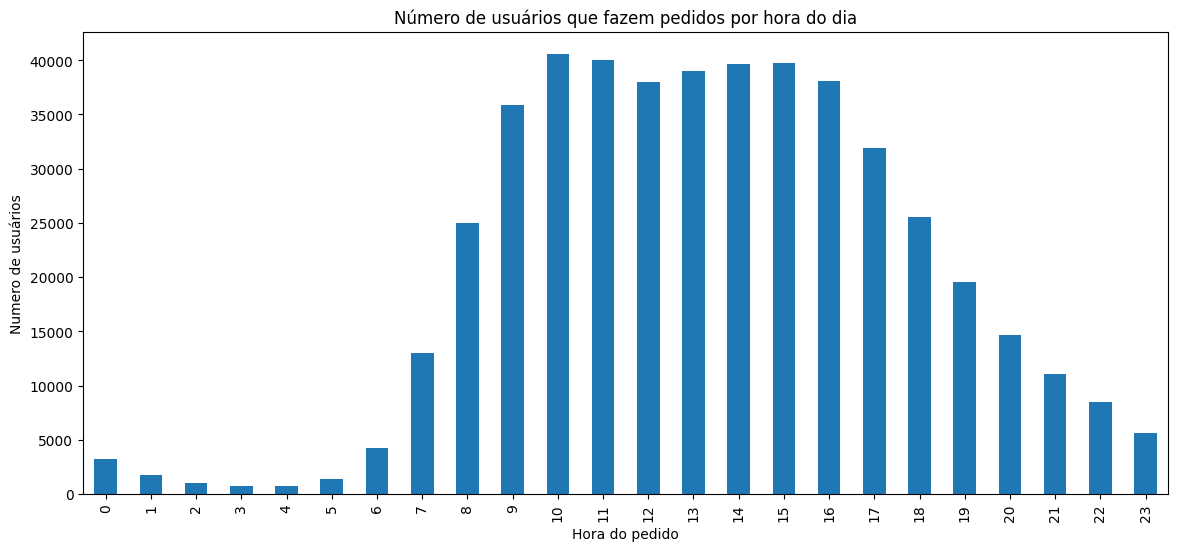

In [36]:


pedidos_por_hora= df_orders.groupby('order_hour_of_day')['order_id'].count()
pedidos_por_hora.plot(kind= 'bar',
                     title= 'Número de usuários que fazem pedidos por hora do dia',
                     xlabel= 'Hora do pedido',
                     ylabel= 'Numero de usuários',
                     figsize=(14, 6))






Escreva suas conclusões aqui
- Os horarios com maior movimento e numero de pedidos é entre as 10h e as 16h

### [A3] Em que dia da semana as pessoas compram produtos alimentícios?

<AxesSubplot:title={'center':'Dias de maiores compras na semana'}, xlabel='Dia do pedido', ylabel='Numero de compras'>

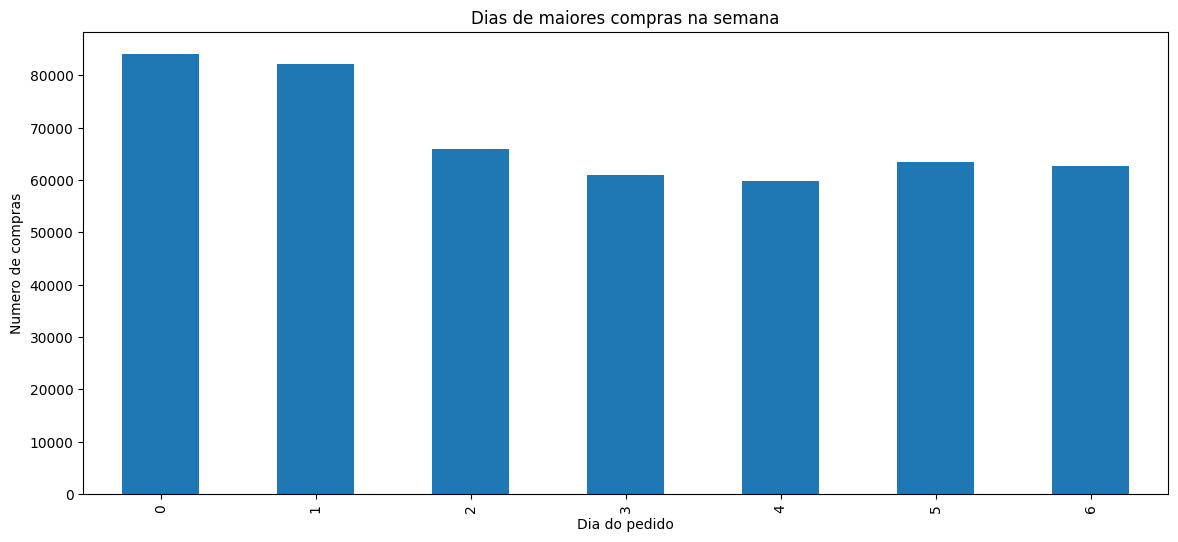

In [37]:


dias_de_compra= df_orders.groupby('order_dow')['order_id'].count()
dias_de_compra.plot(kind= 'bar',
                     title= 'Dias de maiores compras na semana',
                     xlabel= 'Dia do pedido',
                     ylabel= 'Numero de compras',
                     figsize=(14, 6),
                     xticks=range(7))





Compras de produtos alimentícios por dia da semana:
Domingo    33378
Segunda    28708
Terça      21926
Quarta     20087
Quinta     19659
Sexta      20658
Sábado     24230
Name: order_dow, dtype: int64


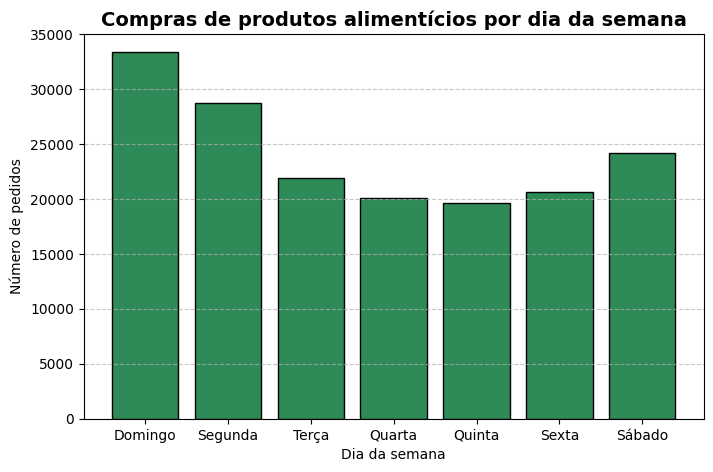

In [55]:
#Codigo gerado pela revisora 

import pandas as pd
import matplotlib.pyplot as plt

orders = pd.read_csv("/datasets/instacart_orders.csv", sep=';')
order_products = pd.read_csv("/datasets/order_products.csv", sep=';')
products = pd.read_csv("/datasets/products.csv", sep=';')
aisles = pd.read_csv("/datasets/aisles.csv", sep=';')
departments = pd.read_csv("/datasets/departments.csv", sep=';')

dados = (
    order_products
    .merge(orders, on='order_id')
    .merge(products, on='product_id')
    .merge(aisles, on='aisle_id')
    .merge(departments, on='department_id')
)

produtos_alimenticios = dados[dados['aisle'].str.contains('food', case=False, na=False)]

compras_por_dia = produtos_alimenticios['order_dow'].value_counts().sort_index()

dias_semana = ['Domingo', 'Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado']
compras_por_dia.index = [dias_semana[i] for i in compras_por_dia.index]

print("Compras de produtos alimentícios por dia da semana:")
print(compras_por_dia)

plt.figure(figsize=(8,5))
plt.bar(compras_por_dia.index, compras_por_dia.values, color='seagreen', edgecolor='black')
plt.title("Compras de produtos alimentícios por dia da semana", fontsize=14, fontweight='bold')
plt.xlabel("Dia da semana")
plt.ylabel("Número de pedidos")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Escreva suas conclusões aqui
- os dias de maiores compras de produtos alimenticios ocorrem no domingo e na segunda feira, pois o numero 0 no gráfico está como domingo.

### [A4] Quanto tempo as pessoas esperam até fazer outro pedido?

Maior quantidade: 51337
Menor quantidade: 2640


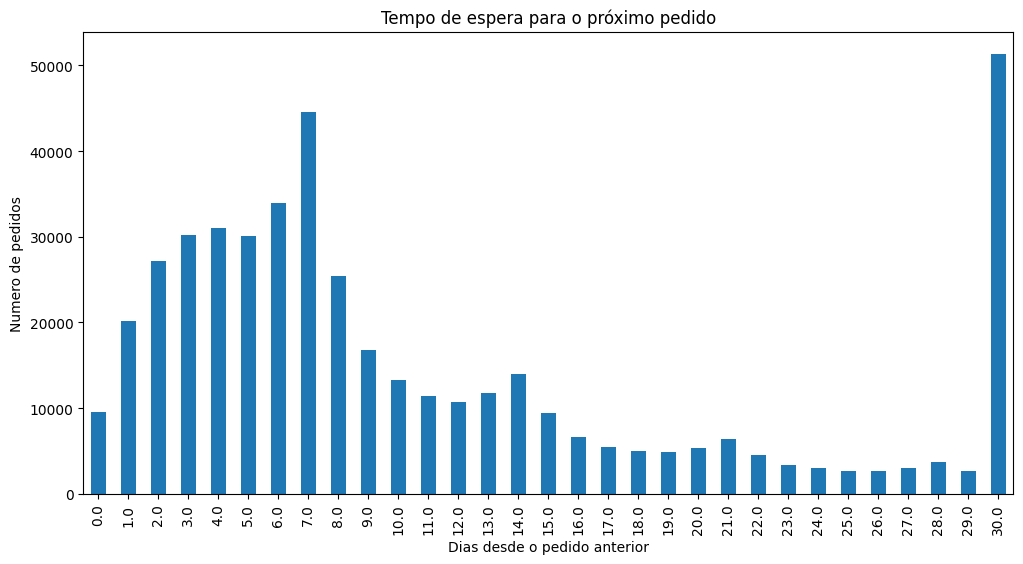

In [38]:
dia_da_ultima_compra = df_orders.groupby('days_since_prior_order')['order_id'].count()

dia_da_ultima_compra.plot (  kind= 'bar',
                            title= 'Tempo de espera para o próximo pedido', 
                            xlabel =  'Dias desde o pedido anterior',
                            ylabel= 'Numero de pedidos',
                            figsize= (12, 6))

print("Maior quantidade:", dia_da_ultima_compra.max())
print("Menor quantidade:", dia_da_ultima_compra.min())



Escreva suas conclusões aqui
- As pessoas retornam em 7 dias e 30 dias para as novas compras, com o volume maior em 30 dias pois a maioria pode estar fazendo as compras do mês. O dia de Maior compras teve quase o dobro de usários comprando que o dia de menor compra

# [B] Médio (é necessário concluir tudo para passar)

1.	Há alguma diferença nas distribuições de `'order_hour_of_day'` nas quartas e sábados? Construa gráficos de barras para ambos os dias no mesmo gráfico e descreva as diferenças que você notou.
2.	Construa um gráfico de distribuição para o número de pedidos que os clientes fazem (ou seja, quantos clientes fizeram apenas 1 pedido, quantos fizeram apenas 2, quantos apenas 3, etc.)
3.	Quais são os 20 produtos comprados com mais frequência? Exiba os IDs e nomes.


### [B1] Diferenças nas quartas e sábados em `'order_hour_of_day'`. Crie gráficos de barras para ambos os dias e descreva as diferenças.

<AxesSubplot:title={'center':'Numeros de pedidos por hora na Quarta-feira'}, xlabel='Hora do dia ', ylabel='Quantidade de pedidos'>

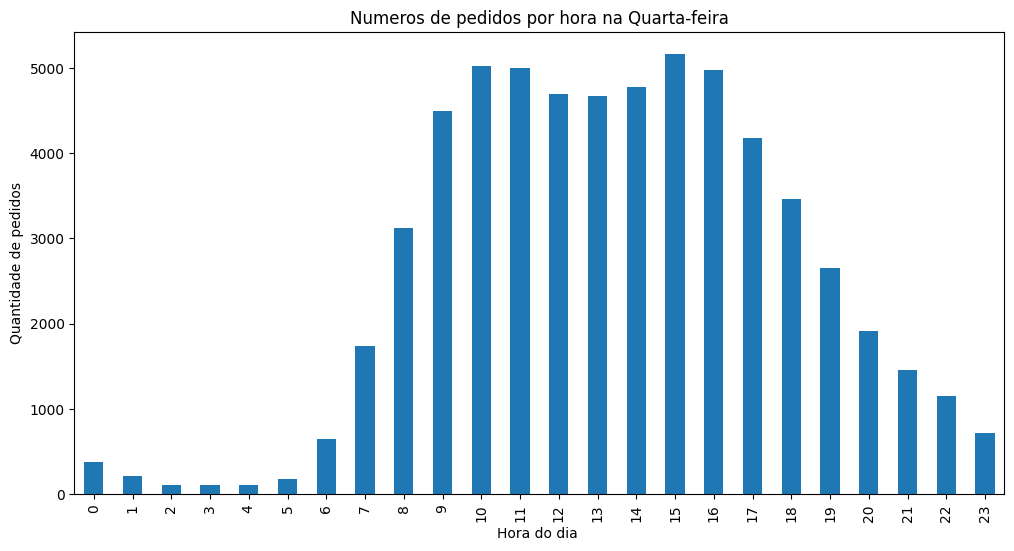

In [39]:


ouders_quarta=  df_orders[df_orders['order_dow'] == 3]
quarta_por_hora = ouders_quarta.groupby('order_hour_of_day')['order_id'].count()
quarta_por_hora.plot( kind= 'bar',
                    title= 'Numeros de pedidos por hora na Quarta-feira', 
                    xlabel =  'Hora do dia ',
                    ylabel= 'Quantidade de pedidos',
                    figsize= (12, 6))




<AxesSubplot:title={'center':'Diferença de pedidos entre Quarta-Feira e Sábado'}, xlabel='Hora do dia', ylabel='Quantidade de pedidos'>

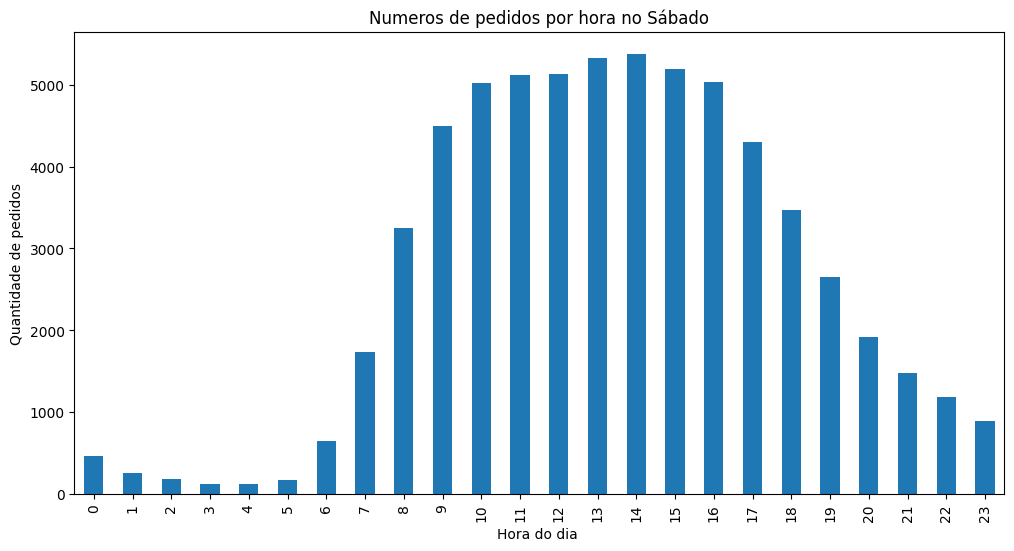

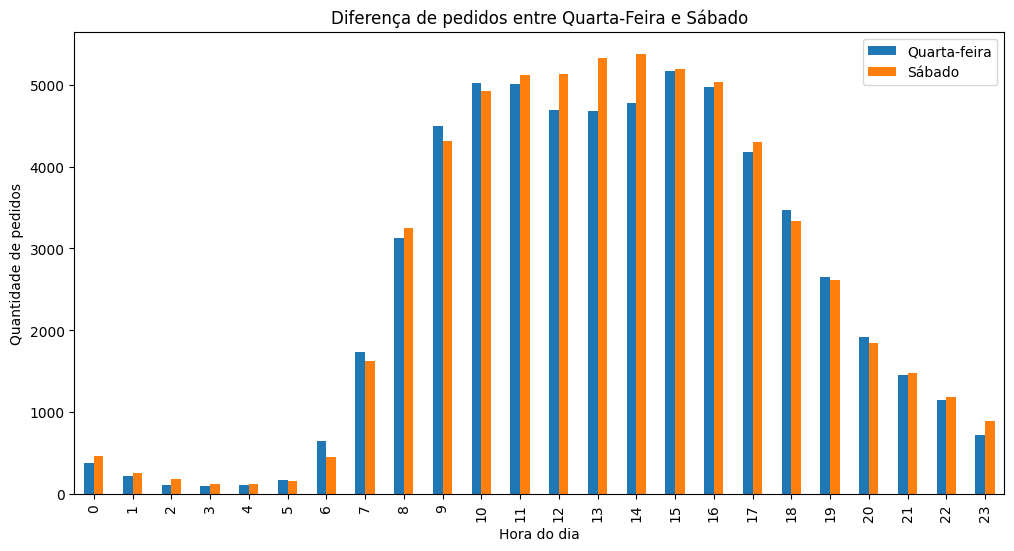

In [40]:


ouders_quarta=  df_orders[df_orders['order_dow'] == 3]
quarta_por_hora = ouders_quarta.groupby('order_hour_of_day')['order_id'].count()
quarta_por_hora.plot( kind= 'bar',
                    title= 'Numeros de pedidos por hora na Quarta-feira', 
                    xlabel =  'Hora do dia ',
                    ylabel= 'Quantidade de pedidos',
                    figsize= (12, 6))

ouders_sábado=  df_orders[df_orders['order_dow'] == 6]
sabado_por_hora= ouders_sábado.groupby('order_hour_of_day')['order_id'].count()
sabado_por_hora.plot( kind= 'bar',
                    title= 'Numeros de pedidos por hora no Sábado', 
                    xlabel =  'Hora do dia ',
                    ylabel= 'Quantidade de pedidos',
                    figsize= (12, 6))
df_combinado = pd.DataFrame({
    'Quarta-feira': quarta_por_hora,
    'Sábado': sabado_por_hora
})
df_combinado.plot( kind= 'bar',

title= 'Diferença de pedidos entre Quarta-Feira e Sábado',
xlabel= 'Hora do dia',
ylabel= 'Quantidade de pedidos',
figsize= (12,6))






Escreva suas conclusões aqui
Os dois dias tem os mesmo horários de pico,mas no sábado ocorre mais pédidos que na quarta-feira.

### [B2] Qual é a distribuição do número de pedidos por cliente?

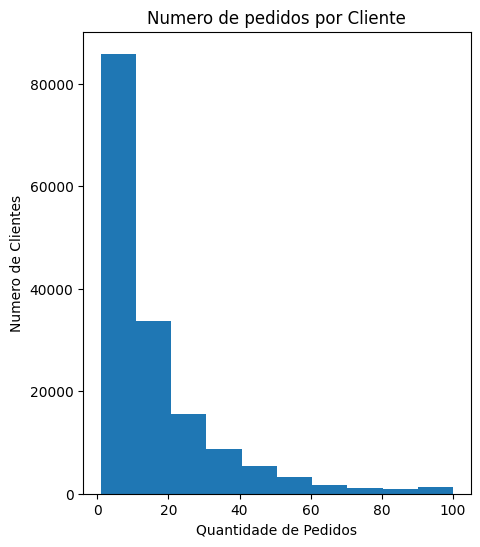

In [41]:


import matplotlib.pyplot as plt
numero_pedidos =df_orders.groupby('user_id')['order_number'].max()
numero_pedidos.plot(kind= 'hist',
                    title= 'Numero de pedidos por Cliente',
                    xlabel= 'Quantidade de pedidos',
                    ylabel= 'Numero de clientes',
              
      figsize= (5,6))
plt.ylabel('Numero de Clientes')
plt.xlabel('Quantidade de Pedidos')
plt.show()




Escreva suas conclusões aqui
o numero de pessoas que fazem de 1 a 10 pedidos e cada vez menos os clientes chegam perto desse numero de pedidos.

### [B3] Quais são os 20 produtos mais populares? Exiba os IDs e nomes.

In [42]:
produtos_mais_vendidos = df_order_products.groupby('product_id')['order_id'].count()
produtos_mais_vendidos = produtos_mais_vendidos.sort_values(ascending= False).head(20).reset_index()
produtos_mais_vendidos

,product_id,order_id
0,24852,66050
1,13176,53297
2,21137,37039
3,21903,33971
4,47209,29773
5,47766,24689
6,47626,21495
7,16797,20018
8,26209,19690
9,27845,19600


In [51]:




produtos_mais_vendidos= produtos_mais_vendidos.merge(df_products, on= 'product_id')
top_20[['product_name', 'product_id']]





,product_name,product_id
0,Banana,24852
1,Bag of Organic Bananas,13176
2,Organic Strawberries,21137
3,Organic Baby Spinach,21903
4,Organic Hass Avocado,47209
5,Organic Avocado,47766
6,Organic Whole Milk,27845
7,Large Lemon,47626
8,Organic Raspberries,27966
9,Strawberries,16797


Escreva suas conclusões aqui
Os produtos mais vendidos são frutas, incluindo organicas.

# [C] Difícil (é necessário concluir pelo menos duas perguntas para passar)

1.	Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?
2.	Quais são os 20 principais itens incluídos mais frequentemente em pedidos repetidos? Exiba os IDs e nomes.
3.	Para cada produto, qual parcela de seus pedidos são repetidos? Crie uma tabela com colunas de ID e nome do produto e a proporção de pedidos repetidos.
4.	Para cada cliente, qual proporção de todos os seus pedidos são repetidos?
5.	Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros? Exiba o ID do produto, nome e o número de vezes que ele foi o primeiro a ser adicionado a um carrinho.


### [C1] Quantos itens as pessoas normalmente compram em um pedido? Como fica a distribuição?

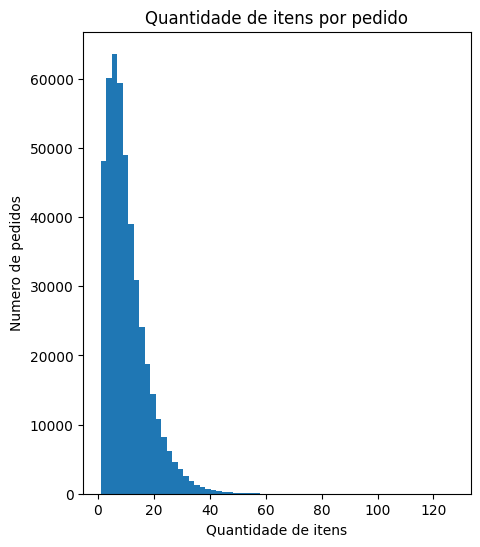

In [44]:

import matplotlib.pyplot as plt
itens_por_pedidos = df_order_products.groupby('order_id')['product_id'].count()
itens_por_pedidos.plot(kind='hist',
                       bins=64,
                     title= 'Quantidade de itens por pedido',
                     xlabel= 'Quantidade de itens',
                     ylabel= 'Numero de pedidos',
                          figsize= (5,6))
plt.ylabel('Numero de pedidos')
plt.xlabel('Quantidade de itens')
plt.show()


In [45]:
print(itens_por_pedidos.describe())


count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: product_id, dtype: float64


In [46]:
print((itens_por_pedidos == 20).sum())


6771


Escreva suas conclusões aqui
A distribuição de pedidos é assimétrica à direita. A média dos pedidos está entre 10.098983 itens por pedido, tendo 10 itens com o maior numero de itens por pedido,diminuindo  para 6.771 o numero de pedidos com 20 itens. Pedidos com muitos itens são muito raros. As pessoas tendem a fazer compras menores a maioria das vezes

### [C2] Quais são os 20 principais itens incluídos com mais frequência em pedidos repetidos? Exiba os IDs e nomes.

In [47]:


reordered_items = df_order_products[df_order_products['reordered'] == 1]
top_20 = reordered_items.groupby('product_id')['order_id'].count()
top_20 = top_20.sort_values(ascending= False).head(20).reset_index()
top_20 = top_20.merge(df_products, on='product_id')
top_20[['product_id', 'product_name']]



,product_id,product_name
0,24852,Banana
1,13176,Bag of Organic Bananas
2,21137,Organic Strawberries
3,21903,Organic Baby Spinach
4,47209,Organic Hass Avocado
5,47766,Organic Avocado
6,27845,Organic Whole Milk
7,47626,Large Lemon
8,27966,Organic Raspberries
9,16797,Strawberries


Escreva suas conclusões aqui
-Frutas são os produtos mais populares e os mais vendidos, aparecem na maioria das compras dos usuários.

### [C3] Para cada produto, qual parcela de todos os pedidos dele são repetidos?

In [48]:

media_de_pedidos = df_order_products.groupby('product_id')['reordered'].mean() * 100
media_de_pedidos= media_de_pedidos.reset_index()
media_de_pedidos= media_de_pedidos.sort_values(by='reordered', ascending= False)
media_de_pedidos = media_de_pedidos.merge(df_orders, on='order_id')

media_de_pedidos[['product_id', 'product_name', 'reordered']]





KeyError: 'order_id'

Escreva suas conclusões aqui
- Mesmo as frutas sendo os produtos que mais vendem, os produtos com maiores recompras são os produtos não saúdaveis(fast-foods), mantendo e procurando uma alimentação rapida e de fácil manutenção. Tirando itens necessários a sobrevivencia como água.

### [C4] Para cada cliente, qual proporção de todos os seus pedidos são repetidos?

In [52]:


media_cliente = df_order_products.groupby('order_id')['reordered'].mean().reset_index()
media_cliente = media_cliente.sort_values(by='reordered', ascending= False)
media_cliente = media_cliente.merge(df_orders, on='order_id')
media_cliente = (media_cliente.groupby('user_id')['reordered'].mean()*100).reset_index()
media_cliente[['user_id', 'reordered']]

,user_id,reordered
0,2,3.846154
1,4,0.000000
2,5,66.666667
3,6,0.000000
4,7,94.444444
...,...,...
149621,206203,22.222222
149622,206206,69.047619
149623,206207,81.500000
149624,206208,73.144307


Escreva suas conclusões aqui

### [C5] Quais são os 20 principais itens que as pessoas colocam nos carrinhos antes de todos os outros?

In [56]:
reordered_items = df_order_products[df_order_products['add_to_cart_order'] 
top_20 = reordered_items.groupby('product_id')['order_id'].count()
top_20 = top_20.sort_values(ascending= False).head(20).reset_index()
top_20 = top_20.merge(df_products, on='product_id')
top_20[['product_id', 'product_name']]


SyntaxError: invalid syntax (158878571.py, line 2)

Escreva suas conclusões aqui

# Conclusão geral do projeto: